# Avance 3: Data Warehouse en Snowflake y pipeline ETL
**Proyecto Integrador M2 · FleetLogix · Tomás Babot**

En este avance:
1. Diseño un **modelo estrella** para analizar las entregas y lo construyo en Snowflake (`2. Scripts/04_dimensional_model.sql`).
2. Construyo un **pipeline ETL automático** PostgreSQL → Snowflake (`2. Scripts/05_etl_pipeline.py`) con control de calidad.
3. Verifico la carga, demuestro el historial de cambios (SCD tipo 2) y consulto el DW.

> Todas las salidas de este notebook vienen de la cuenta real de Snowflake (región AWS sa-east-1).
> La conexión usa un **par de llaves** (la privada queda en `keys/`, fuera del repositorio), no una contraseña.

## 1. Diseño del modelo estrella

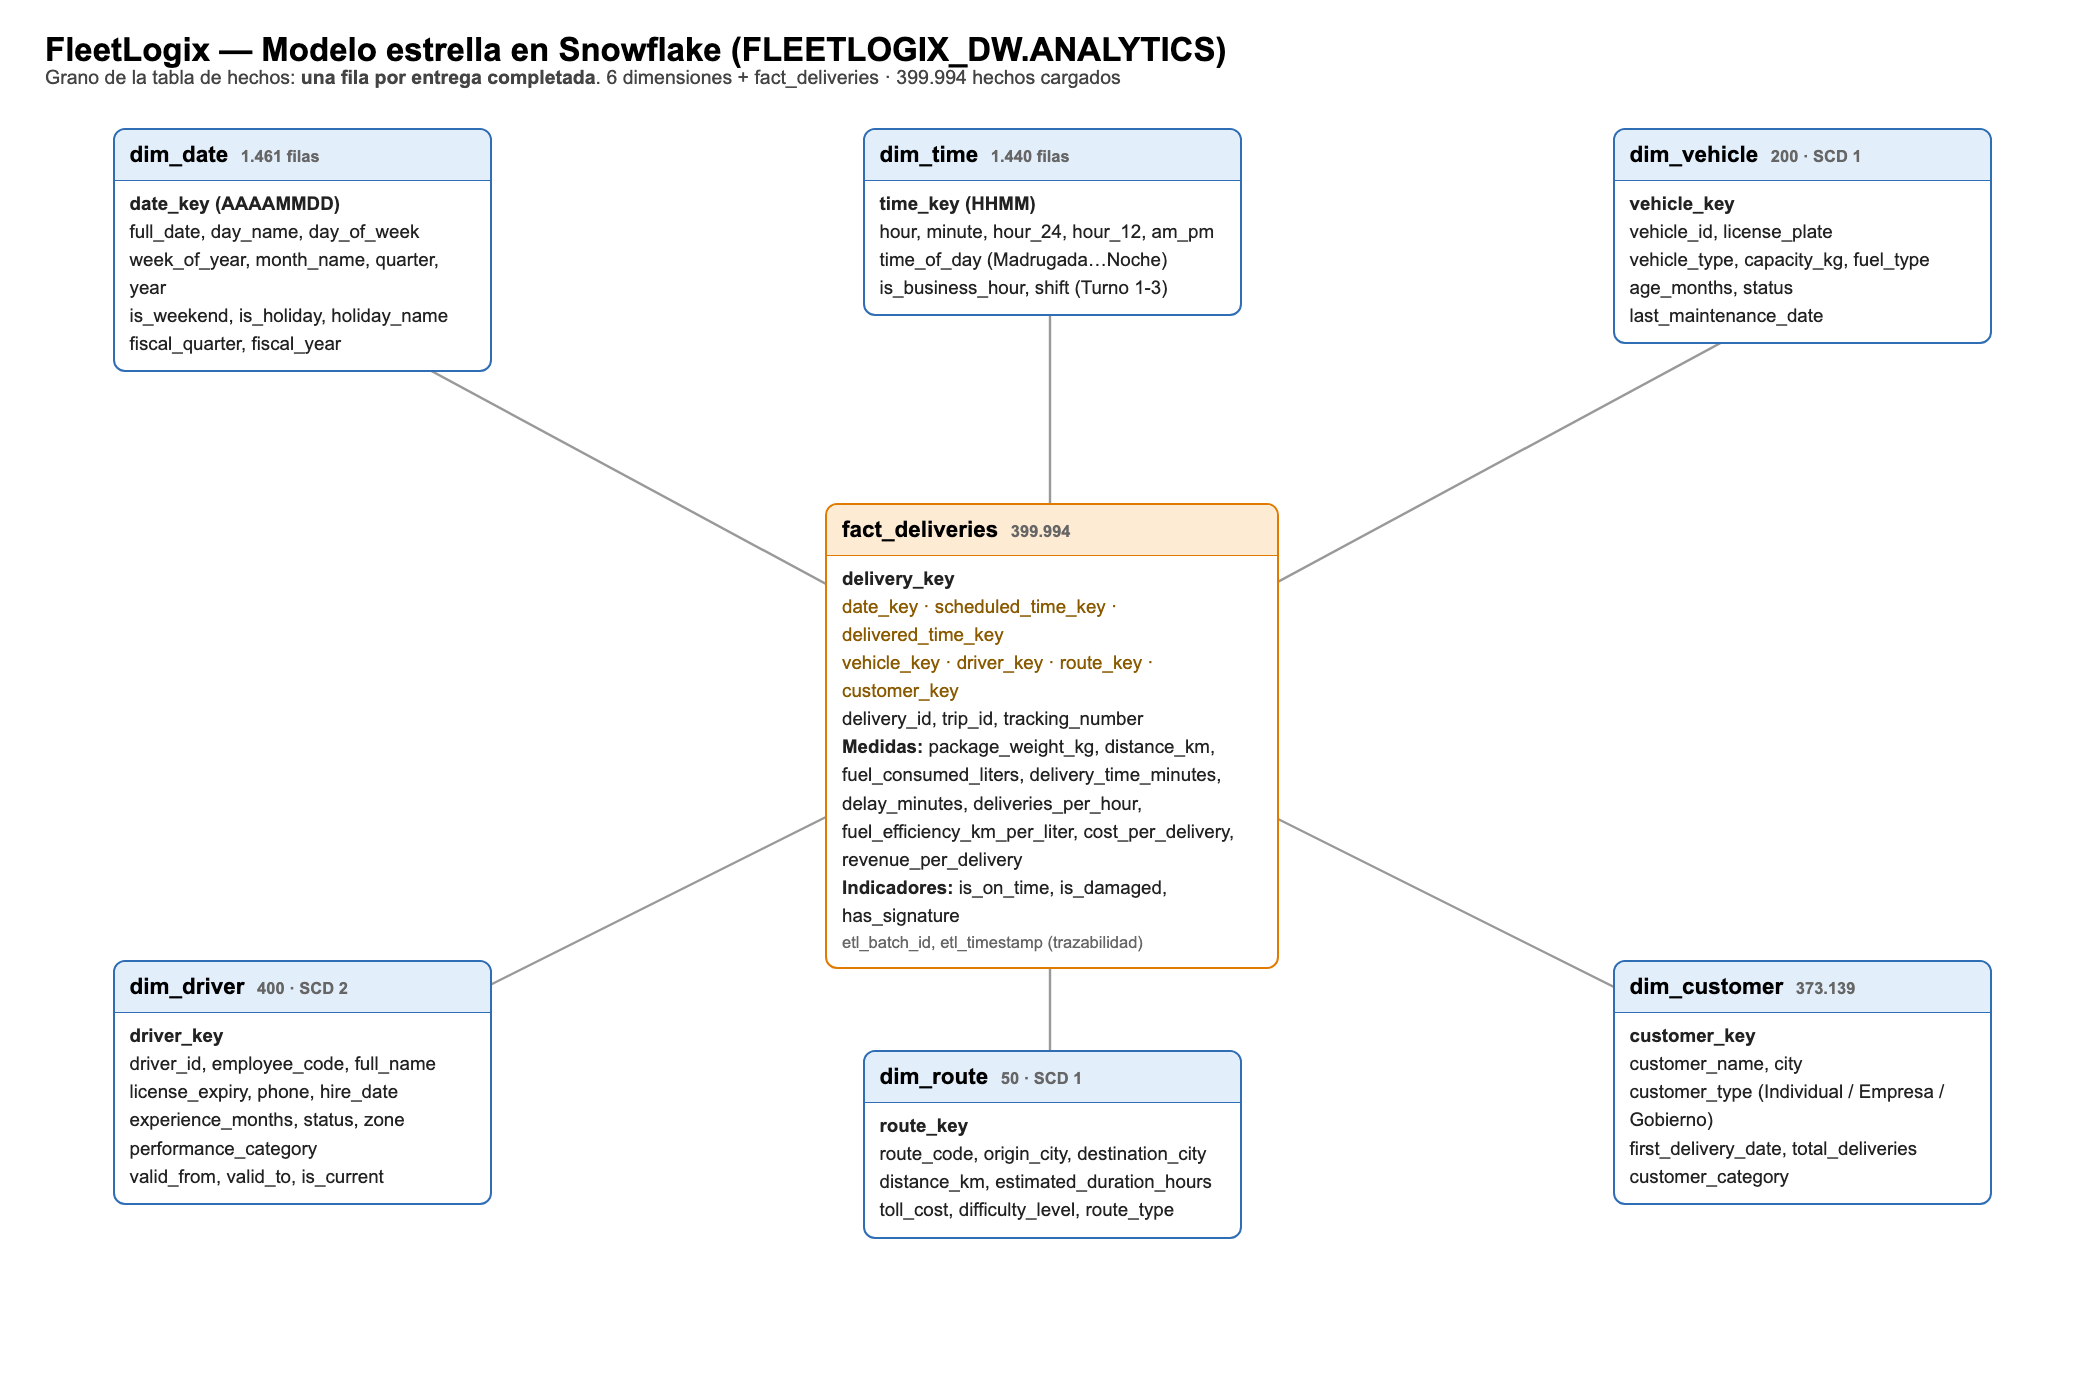

In [1]:
from IPython.display import Image
Image('../3. Documentación/img/modelo_estrella.png', width=900)

**Decisiones de diseño**

| Decisión | Elección | Por qué |
|---|---|---|
| Grano (qué es una fila de hechos) | **una entrega completada** | es la unidad que el negocio mide (puntualidad, ingreso, costo); se puede sumar hacia arriba a viaje, día, ruta o conductor |
| Esquema | **estrella** (dimensiones sin normalizar) | menos JOIN que un copo de nieve → consultas más simples y rápidas para analistas |
| Claves | **surrogate keys** (`*_key`) distintas de los ID de origen | permiten guardar varias versiones de un conductor (SCD2) y no dependen del sistema origen |
| dim_date / dim_time | claves inteligentes `AAAAMMDD` y `HHMM` | se calculan directo desde la fecha, sin buscar en la dimensión |
| Combustible y distancia | se **reparten** entre las entregas del viaje | son datos del viaje; si se copiaran enteros en cada entrega, al sumar se contarían 4 veces |
| dim_vehicle, dim_route | **SCD tipo 1** (se sobrescriben) | interesa solo el estado actual |
| dim_driver | **SCD tipo 2** (historial) | si un conductor cambia de zona, estado, licencia o teléfono, las entregas viejas siguen asociadas a cómo era *en ese momento* |
| dim_customer | se agregan solo clientes nuevos | el origen no tiene tabla de clientes: se construye a partir del nombre + ciudad de la entrega |

**Configuración de Snowflake** (en `04_dimensional_model.sql`):
- Warehouse **X-Small** con `AUTO_SUSPEND = 60` (se apaga solo al minuto sin uso) y `AUTO_RESUME`: solo se pagan los segundos de uso.
- **Multi-cluster** (1 a 2): si muchos analistas consultan a la vez, Snowflake agrega un segundo cluster automáticamente.
- **Time Travel de 30 días** en las tablas del modelo: se puede consultar o recuperar la tabla como estaba hasta 30 días atrás.
- **Vistas seguras** por rol: `SALES_ANALYST` ve `v_sales_deliveries` (sin clientes de Gobierno) y `OPERATIONS_ANALYST` ve `v_operations_deliveries`.

In [2]:
import os, importlib.util
import pandas as pd
import matplotlib.pyplot as plt
import psycopg2
import snowflake.connector

# Reutilizo la configuración y el código del script ETL (lee el archivo .env)
os.chdir('../2. Scripts')
spec = importlib.util.spec_from_file_location('etl', '05_etl_pipeline.py')
etl = importlib.util.module_from_spec(spec)
spec.loader.exec_module(etl)

sf = snowflake.connector.connect(**etl.SNOWFLAKE_CONFIG)
pg = psycopg2.connect(**etl.POSTGRES_CONFIG)

def snow(sql):
    cur = sf.cursor()
    cur.execute(sql)
    return pd.DataFrame(cur.fetchall(), columns=[c[0].lower() for c in cur.description])

def postgres(sql):
    cur = pg.cursor()
    cur.execute(sql)
    return pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])

snow('SELECT CURRENT_ROLE() AS rol, CURRENT_WAREHOUSE() AS warehouse, CURRENT_DATABASE() AS base, CURRENT_SCHEMA() AS esquema, CURRENT_REGION() AS region')

/opt/anaconda3/envs/anaconda-ml-ai/lib/python3.11/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


2026-11-17 11:23:37,342 - WARNING - Proxy configuration: using environment variable proxy settings


2026-11-17 11:23:37,357 - WARNING - failed to load region from IMDS err=failed to load IMDS session token: dispatch failure: io error: error sending request for url (http://169.254.169.254/latest/api/token): client error (Connect): tcp connect error: No route to host (os error 65) (FailedToLoadToken(FailedToLoadToken { source: DispatchFailure(DispatchFailure { source: ConnectorError { kind: Io, source: reqwest::Error { kind: Request, url: "http://169.254.169.254/latest/api/token", source: hyper_util::client::legacy::Error(Connect, ConnectError("tcp connect error", 169.254.169.254:80, Os { code: 65, kind: HostUnreachable, message: "No route to host" })) }, connection: Unknown } }) }))


2026-11-17 11:23:37,358 - WARNING - failed to load region from IMDS err=failed to load IMDS session token: dispatch failure: io error: error sending request for url (http://169.254.169.254/latest/api/token): client error (Connect): tcp connect error: Host is down (os error 64) (FailedToLoadToken(FailedToLoadToken { source: DispatchFailure(DispatchFailure { source: ConnectorError { kind: Io, source: reqwest::Error { kind: Request, url: "http://169.254.169.254/latest/api/token", source: hyper_util::client::legacy::Error(Connect, ConnectError("tcp connect error", 169.254.169.254:80, Os { code: 64, kind: Uncategorized, message: "Host is down" })) }, connection: Unknown } }) }))


,rol,warehouse,base,esquema,region
0,ACCOUNTADMIN,FLEETLOGIX_WH,FLEETLOGIX_DW,ANALYTICS,AWS_SA_EAST_1


### 1.1 Objetos creados en Snowflake

In [3]:
tablas = snow('SHOW TABLES IN SCHEMA FLEETLOGIX_DW.ANALYTICS')
tablas[['name', 'rows', 'bytes', 'retention_time']].rename(columns={'retention_time': 'time_travel_dias'})

,name,rows,bytes,time_travel_dias
0,AGG_DAILY_TOTALS,731,13312,1
1,DIM_CUSTOMER,373139,3198976,30
2,DIM_DATE,1461,15872,30
3,DIM_DRIVER,400,18944,30
4,DIM_ROUTE,50,2560,30
5,DIM_TIME,1440,18432,30
6,DIM_VEHICLE,200,5632,30
7,FACT_DELIVERIES,399994,11184128,30
8,STAGING_DAILY_LOAD,0,0,1


In [4]:
wh = snow("SHOW WAREHOUSES LIKE 'FLEETLOGIX_WH'")
wh[['name', 'size', 'auto_suspend', 'auto_resume', 'min_cluster_count', 'max_cluster_count', 'scaling_policy']]

,name,size,auto_suspend,auto_resume,min_cluster_count,max_cluster_count,scaling_policy
0,FLEETLOGIX_WH,X-Small,60,true,1,2,STANDARD


In [5]:
display(snow("SELECT table_name AS vista, is_secure FROM FLEETLOGIX_DW.INFORMATION_SCHEMA.VIEWS WHERE table_schema = 'ANALYTICS'"))
permisos = pd.concat([snow('SHOW GRANTS TO ROLE SALES_ANALYST'), snow('SHOW GRANTS TO ROLE OPERATIONS_ANALYST')])
permisos[['grantee_name', 'privilege', 'granted_on', 'name']]

,vista,is_secure
0,V_OPERATIONS_DELIVERIES,YES
1,V_SALES_DELIVERIES,YES


,grantee_name,privilege,granted_on,name
0,SALES_ANALYST,USAGE,DATABASE,FLEETLOGIX_DW
1,SALES_ANALYST,USAGE,SCHEMA,FLEETLOGIX_DW.ANALYTICS
2,SALES_ANALYST,SELECT,VIEW,FLEETLOGIX_DW.ANALYTICS.V_SALES_DELIVERIES
3,SALES_ANALYST,USAGE,WAREHOUSE,FLEETLOGIX_WH
0,OPERATIONS_ANALYST,USAGE,DATABASE,FLEETLOGIX_DW
1,OPERATIONS_ANALYST,USAGE,SCHEMA,FLEETLOGIX_DW.ANALYTICS
2,OPERATIONS_ANALYST,SELECT,VIEW,FLEETLOGIX_DW.ANALYTICS.V_OPERATIONS_DELIVERIES
3,OPERATIONS_ANALYST,USAGE,WAREHOUSE,FLEETLOGIX_WH


### 1.2 Capturas del Data Warehouse en Snowflake

Las tablas creadas en `FLEETLOGIX_DW.ANALYTICS`, con la cantidad de filas, el tamaño y los días de Time Travel
(30 en las tablas principales; 1 en la tabla de totales y en la de staging, que se pueden recalcular):

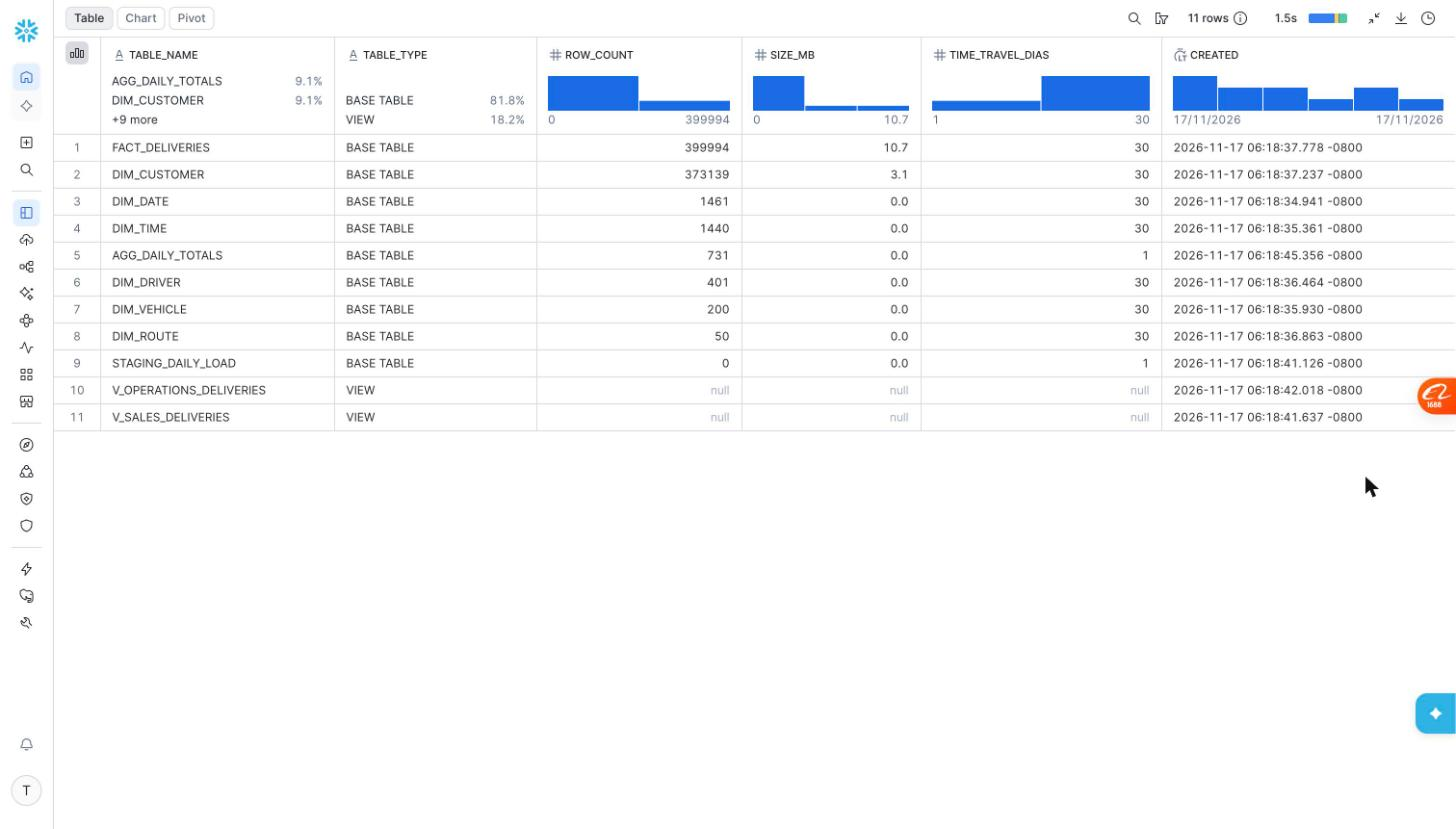

Una consulta analítica que une la tabla de hechos con `dim_route`. Las entregas de las 5 ciudades suman 399.994,
igual que en PostgreSQL:

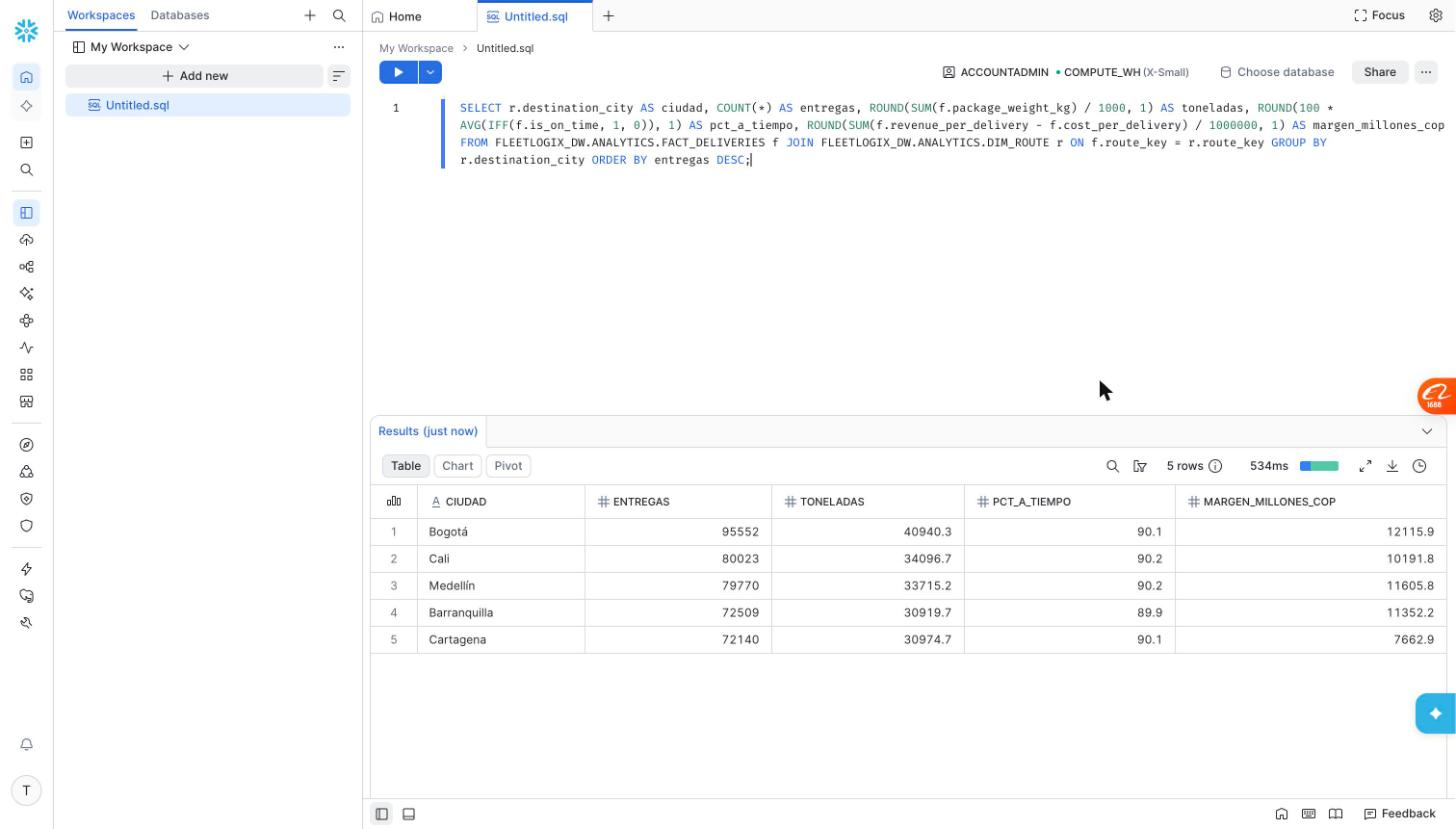

## 2. El pipeline ETL (`05_etl_pipeline.py`)

| Etapa | Qué hace |
|---|---|
| **Extract** | Lee de PostgreSQL las entregas `delivered` del período, unidas con su viaje, ruta, vehículo y conductor. Trae también las tablas maestras para las dimensiones. |
| **Transform** | Calcula las métricas (tabla de abajo), descarta filas imposibles (control de calidad) y arma las claves de fecha y hora. Construye las 6 dimensiones con pandas. |
| **Load** | Sube cada tabla con `write_pandas` (archivos Parquet + `COPY INTO`, mucho más rápido que fila por fila). Primero dimensiones, después hechos. |
| **Post-carga** | Recalcula `agg_daily_totals` (totales por día) para que los reportes no recorran toda la tabla de hechos. |

**Métricas calculadas**

| Métrica | Fórmula |
|---|---|
| `delivery_time_minutes` | entrega real − salida del viaje |
| `delay_minutes` | entrega real − hora programada (0 si llegó antes) |
| `is_on_time` | demora ≤ 30 minutos |
| `deliveries_per_hour` | entregas del viaje ÷ horas que duró el viaje |
| `fuel_efficiency_km_per_liter` | km de la ruta ÷ litros del viaje |
| `cost_per_delivery` | (litros × 5.000 COP + peaje) ÷ entregas del viaje |
| `revenue_per_delivery` | 20.000 COP + 500 COP por kg |

**Automatización**
- `python 05_etl_pipeline.py --full` → carga inicial (toda la historia).
- `python 05_etl_pipeline.py` → carga **incremental** de las entregas de **ayer**.
- `python 05_etl_pipeline.py --schedule` → queda corriendo y ejecuta todos los días a las **02:00** (librería `schedule`).
- Alternativa en un servidor: cron `0 2 * * * cd ".../2. Scripts" && python 05_etl_pipeline.py >> etl_cron.log 2>&1`.

**Robustez**
- **Idempotente:** antes de cargar un período borra lo que ya hubiera de esas fechas → correrlo dos veces no duplica.
- Cada carga lleva un `etl_batch_id` para saber de qué corrida vino cada fila.
- Todo queda registrado en `etl_pipeline.log` y los errores no cortan sin cerrar las conexiones (`try / finally`).

### 2.1 Log de las corridas

In [6]:
with open('etl_pipeline.log', encoding='utf-8') as f:
    lineas = [l.rstrip() for l in f if any(p in l for p in ('Iniciando', 'Extraídas', 'Transformadas', 'dim_', 'Cargadas', 'terminado', 'ERROR', 'Calidad'))]
print('\n'.join(lineas[-20:]))

2026-11-17 11:18:52,725 - INFO - Iniciando ETL - batch 1794925132 - modo completo
2026-11-17 11:18:57,312 - INFO - Extraídas 399,994 entregas
2026-11-17 11:18:58,435 - INFO - Transformadas 399,994 entregas
2026-11-17 11:19:16,645 - INFO - dim_driver: 400 versiones nuevas, 0 cerradas (SCD2)
2026-11-17 11:19:31,807 - INFO - dim_customer: 373,139 clientes nuevos
2026-11-17 11:19:56,521 - INFO - Cargadas 399,994 filas en fact_deliveries
2026-11-17 11:19:59,060 - INFO - ETL terminado en 66.3 s - métricas: {"records_extracted": 399994, "records_rejected": 0, "records_transformed": 399994, "records_loaded": 399994, "errors": 0}
2026-11-17 11:20:42,176 - INFO - Iniciando ETL - batch 1794925242 - modo incremental
2026-11-17 11:20:43,029 - INFO - Extraídas 257 entregas
2026-11-17 11:20:43,037 - INFO - Transformadas 257 entregas
2026-11-17 11:20:53,649 - INFO - dim_driver: 0 versiones nuevas, 0 cerradas (SCD2)
2026-11-17 11:21:08,233 - INFO - Cargadas 257 filas en fact_deliveries
2026-11-17 11:21

## 3. Control de calidad de la carga
### 3.1 Integridad: ninguna fila de hechos sin su dimensión

In [7]:
snow('''
    SELECT COUNT(*) AS filas_hechos,
           COUNT_IF(d.date_key IS NULL)      AS sin_fecha,
           COUNT_IF(t.time_key IS NULL)      AS sin_hora,
           COUNT_IF(v.vehicle_key IS NULL)   AS sin_vehiculo,
           COUNT_IF(dr.driver_key IS NULL)   AS sin_conductor,
           COUNT_IF(r.route_key IS NULL)     AS sin_ruta,
           COUNT_IF(c.customer_key IS NULL)  AS sin_cliente
    FROM fact_deliveries f
    LEFT JOIN dim_date d      ON f.date_key = d.date_key
    LEFT JOIN dim_time t      ON f.scheduled_time_key = t.time_key
    LEFT JOIN dim_vehicle v   ON f.vehicle_key = v.vehicle_key
    LEFT JOIN dim_driver dr   ON f.driver_key = dr.driver_key
    LEFT JOIN dim_route r     ON f.route_key = r.route_key
    LEFT JOIN dim_customer c  ON f.customer_key = c.customer_key
''')

,filas_hechos,sin_fecha,sin_hora,sin_vehiculo,sin_conductor,sin_ruta,sin_cliente
0,399994,0,0,0,0,0,0


### 3.2 Conciliación: los totales del DW coinciden con PostgreSQL

In [8]:
origen = postgres('''
    SELECT COUNT(*) AS entregas, SUM(d.package_weight_kg) AS peso_kg,
           ROUND(100.0 * AVG(CASE WHEN d.delivered_datetime <= d.scheduled_datetime + INTERVAL '30 minutes' THEN 1 ELSE 0 END), 2) AS a_tiempo_pct
    FROM deliveries d WHERE d.delivery_status = 'delivered'
''')
combustible_origen = postgres('''
    SELECT SUM(t.fuel_consumed_liters) AS combustible_l FROM trips t
    WHERE EXISTS (SELECT 1 FROM deliveries d WHERE d.trip_id = t.trip_id AND d.delivery_status = 'delivered')
''')
origen['combustible_l'] = combustible_origen['combustible_l']

destino = snow('''
    SELECT COUNT(*) AS entregas, SUM(package_weight_kg) AS peso_kg,
           ROUND(100 * AVG(IFF(is_on_time, 1, 0)), 2) AS a_tiempo_pct, SUM(fuel_consumed_liters) AS combustible_l
    FROM fact_deliveries
''')
conciliacion = pd.concat([origen.assign(fuente='PostgreSQL'), destino.assign(fuente='Snowflake')]).set_index('fuente').astype(float)
conciliacion.loc['diferencia_%'] = (100 * (conciliacion.iloc[1] / conciliacion.iloc[0] - 1)).round(5)
conciliacion

,entregas,peso_kg,a_tiempo_pct,combustible_l
fuente,,,,
PostgreSQL,399994.0,1.706466e+08,90.13,6.537192e+06
Snowflake,399994.0,1.706466e+08,90.13,6.537194e+06
diferencia_%,0.0,0.000000e+00,0.00,3.000000e-05


Coinciden la cantidad de entregas, el peso y el % a tiempo. El combustible difiere en milésimas de punto porcentual:
es el redondeo a 2 decimales al repartir los litros de cada viaje entre sus entregas.

### 3.3 La tabla de totales diarios coincide con la tabla de hechos

In [9]:
pd.concat([
    snow('SELECT SUM(total_deliveries) AS entregas, SUM(total_revenue) AS ingresos FROM agg_daily_totals').assign(tabla='agg_daily_totals'),
    snow('SELECT COUNT(*) AS entregas, SUM(revenue_per_delivery) AS ingresos FROM fact_deliveries').assign(tabla='fact_deliveries'),
]).set_index('tabla')

,entregas,ingresos
tabla,,
agg_daily_totals,399994,93323159225.00
fact_deliveries,399994,93323159225.00


### 3.4 Idempotencia: repetir la carga de un día no duplica filas

In [10]:
antes = snow('SELECT COUNT(*) AS filas, COUNT(DISTINCT delivery_id) AS entregas_distintas FROM fact_deliveries')
metricas = etl.FleetLogixETL().run_etl(fecha=etl.date(2026, 11, 16))     # carga incremental de un día
despues = snow('SELECT COUNT(*) AS filas, COUNT(DISTINCT delivery_id) AS entregas_distintas FROM fact_deliveries')
display(pd.DataFrame([metricas]))
pd.concat([antes.assign(momento='antes'), despues.assign(momento='después de recargar el 16/11')]).set_index('momento')

2026-11-17 11:23:44,408 - INFO - Iniciando ETL - batch 1794925424 - modo incremental


2026-11-17 11:23:44,418 - INFO - Conectado a PostgreSQL


/opt/anaconda3/envs/anaconda-ml-ai/lib/python3.11/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(
2026-11-17 11:23:44,427 - WARNING - Proxy configuration: using environment variable proxy settings


2026-11-17 11:23:44,984 - INFO - Conectado a Snowflake


2026-11-17 11:23:44,985 - INFO - Extrayendo entregas desde 2026-11-16 hasta 2026-11-17...


/Users/tomasbabot/Documents/Data Science Soy Henry /Modulo 2/ProyectoM2_TomasBabot/2. Scripts/05_etl_pipeline.py:158: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, self.pg_conn, params=(desde, hasta))
2026-11-17 11:23:45,034 - INFO - Extraídas 257 entregas


... (14 outputs left out)

2026-11-17 11:24:05,837 - INFO - Conexiones cerradas


2026-11-17 11:24:05,838 - INFO - ETL terminado en 21.4 s - métricas: {"records_extracted": 257, "records_rejected": 0, "records_transformed": 257, "records_loaded": 257, "errors": 0}


,records_extracted,records_rejected,records_transformed,records_loaded,errors
0,257,0,257,257,0


,filas,entregas_distintas
momento,,
antes,399994,399994
después de recargar el 16/11,399994,399994


## 4. Historial de cambios en conductores (SCD tipo 2)

Simulo que un conductor **cambió de teléfono** en el sistema operativo (PostgreSQL) y corro el ETL incremental.
La versión anterior del conductor no se borra: se **cierra** (`valid_to` = ayer, `is_current` = FALSE) y se agrega una versión nueva.
Así las entregas viejas siguen apuntando a la versión vieja.

> Nota: este cambio queda guardado en la base de datos de origen (es un dato sintético).

In [11]:
conductor = int(postgres("SELECT MIN(driver_id) AS id FROM drivers WHERE status = 'active'")['id'][0])
print('Conductor elegido:', conductor)
snow(f'SELECT driver_key, driver_id, full_name, phone, zone, valid_from, valid_to, is_current FROM dim_driver WHERE driver_id = {conductor} ORDER BY driver_key')

Conductor elegido: 1


,driver_key,driver_id,full_name,phone,zone,valid_from,valid_to,is_current
0,1,1,Fernando Salcedo,3994310083,Barranquilla,2024-01-17,9999-12-31,True


In [12]:
cur = pg.cursor()
cur.execute("UPDATE drivers SET phone = '+57 300 000 0001' WHERE driver_id = %s", (conductor,))
pg.commit()

etl.FleetLogixETL().run_etl(fecha=etl.date(2026, 11, 16))
snow(f'SELECT driver_key, driver_id, full_name, phone, zone, valid_from, valid_to, is_current FROM dim_driver WHERE driver_id = {conductor} ORDER BY driver_key')

2026-11-17 11:24:06,454 - INFO - Iniciando ETL - batch 1794925446 - modo incremental


2026-11-17 11:24:06,461 - INFO - Conectado a PostgreSQL


/opt/anaconda3/envs/anaconda-ml-ai/lib/python3.11/site-packages/snowflake/connector/connection/_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(
2026-11-17 11:24:06,467 - WARNING - Proxy configuration: using environment variable proxy settings


2026-11-17 11:24:06,891 - INFO - Conectado a Snowflake


2026-11-17 11:24:06,892 - INFO - Extrayendo entregas desde 2026-11-16 hasta 2026-11-17...


/Users/tomasbabot/Documents/Data Science Soy Henry /Modulo 2/ProyectoM2_TomasBabot/2. Scripts/05_etl_pipeline.py:158: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, self.pg_conn, params=(desde, hasta))
2026-11-17 11:24:06,938 - INFO - Extraídas 257 entregas


... (16 outputs left out)

2026-11-17 11:24:29,471 - INFO - Totales diarios calculados


2026-11-17 11:24:29,732 - INFO - Conexiones cerradas


2026-11-17 11:24:29,732 - INFO - ETL terminado en 23.3 s - métricas: {"records_extracted": 257, "records_rejected": 0, "records_transformed": 257, "records_loaded": 257, "errors": 0}


,driver_key,driver_id,full_name,phone,zone,valid_from,valid_to,is_current
0,1,1,Fernando Salcedo,3994310083,Barranquilla,2024-01-17,2026-11-16,False
1,401,1,Fernando Salcedo,+57 300 000 0001,Barranquilla,2026-11-17,9999-12-31,True


In [13]:
snow('SELECT COUNT(*) AS versiones, COUNT_IF(is_current) AS vigentes, COUNT(DISTINCT driver_id) AS conductores FROM dim_driver')

,versiones,vigentes,conductores
0,401,400,400


## 5. Consultas analíticas sobre el Data Warehouse

### 5.1 Evolución mensual (desde la tabla pre-calculada)

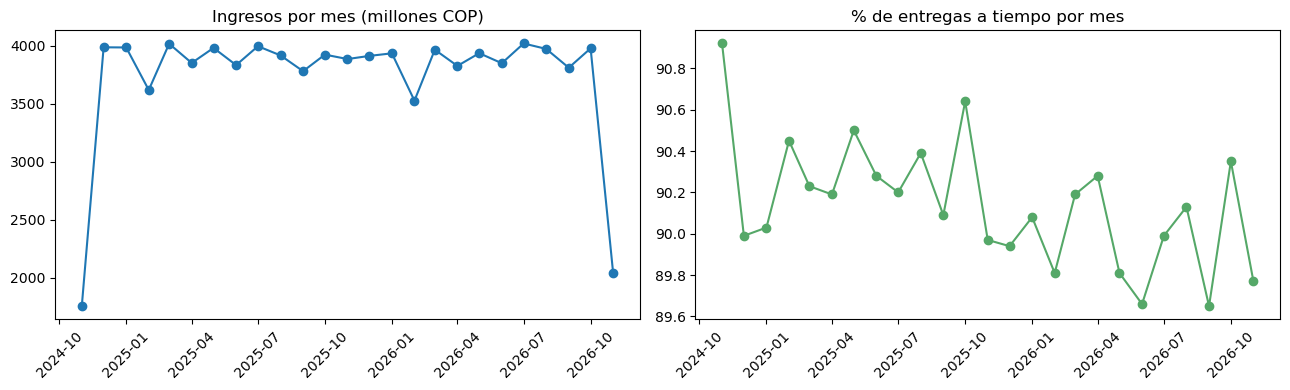

,mes,entregas,a_tiempo_pct,ingresos_millones_cop
19,2026-06-01,16490,89.66,3850.3
20,2026-07-01,17001,89.99,4020.8
21,2026-08-01,17077,90.13,3973.8
22,2026-09-01,16462,89.65,3811.6
23,2026-10-01,17045,90.35,3978.8
24,2026-11-01,8419,89.77,2037.1


In [14]:
mensual = snow('''
    SELECT DATE_TRUNC('month', summary_date) AS mes,
           SUM(total_deliveries) AS entregas,
           ROUND(100 * SUM(on_time_deliveries) / SUM(total_deliveries), 2) AS a_tiempo_pct,
           ROUND(SUM(total_revenue) / 1e6, 1) AS ingresos_millones_cop
    FROM agg_daily_totals
    GROUP BY 1 ORDER BY 1
''')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(mensual['mes'], mensual['ingresos_millones_cop'], marker='o'); ax[0].set_title('Ingresos por mes (millones COP)')
ax[1].plot(mensual['mes'], mensual['a_tiempo_pct'], marker='o', color='#55A868'); ax[1].set_title('% de entregas a tiempo por mes')
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
mensual.tail(6)

### 5.2 Rentabilidad por ciudad de destino

In [15]:
snow('''
    SELECT r.destination_city AS ciudad,
           COUNT(*) AS entregas,
           ROUND(SUM(f.revenue_per_delivery) / 1e6, 1) AS ingresos_mill,
           ROUND(SUM(f.cost_per_delivery) / 1e6, 1) AS costo_mill,
           ROUND(100 * (1 - SUM(f.cost_per_delivery) / SUM(f.revenue_per_delivery)), 1) AS margen_pct,
           ROUND(100 * AVG(IFF(f.is_on_time, 1, 0)), 2) AS a_tiempo_pct
    FROM fact_deliveries f JOIN dim_route r ON f.route_key = r.route_key
    GROUP BY 1 ORDER BY ingresos_mill DESC
''')

,ciudad,entregas,ingresos_mill,costo_mill,margen_pct,a_tiempo_pct
0,Bogotá,95552,22381.2,10265.3,54.1,90.13
1,Cali,80023,18648.8,8457.0,54.7,90.22
2,Medellín,79770,18453.0,6847.2,62.9,90.22
3,Cartagena,72140,16930.2,9267.2,45.3,90.13
4,Barranquilla,72509,16910.0,5557.8,67.1,89.93


**Interpretación:** Bogotá concentra la mayor parte de los ingresos, pero **Barranquilla (67%) y Medellín (63%) tienen el mejor margen**.
Cartagena tiene el peor (45%) porque recibe rutas largas con mucho combustible y peaje (por ejemplo Bogotá → Cartagena, de más de 1.000 km).
Conviene revisar la tarifa de esas rutas, que hoy depende solo del peso y no de la distancia.

### 5.3 Puntualidad por día de la semana y turno

In [16]:
pivote = snow('''
    SELECT d.day_of_week, d.day_name AS dia, t.shift AS turno,
           ROUND(100 * AVG(IFF(f.is_on_time, 1, 0)), 2) AS a_tiempo_pct
    FROM fact_deliveries f
    JOIN dim_date d ON f.date_key = d.date_key
    JOIN dim_time t ON f.scheduled_time_key = t.time_key
    GROUP BY 1, 2, 3
''').pivot_table(index=['day_of_week', 'dia'], columns='turno', values='a_tiempo_pct').droplevel(0)
pivote

turno,Turno 1,Turno 2,Turno 3
dia,,,
Lunes,90.21,89.74,89.99
Martes,90.14,90.38,90.54
Miércoles,89.74,89.99,90.32
Jueves,90.22,90.19,90.09
Viernes,89.89,90.21,90.47
Sábado,90.08,90.05,90.25
Domingo,89.95,90.36,90.27


**Interpretación:** la puntualidad es pareja (~90%) en todos los días y turnos. Con estos datos no hay un día o turno problemático
donde concentrar recursos. En datos reales este cruce es el primero que conviene mirar para reasignar personal.

### 5.4 Desempeño por tipo de vehículo

In [17]:
snow('''
    SELECT v.vehicle_type AS tipo,
           COUNT(*) AS entregas,
           ROUND(AVG(f.package_weight_kg), 1) AS peso_prom_kg,
           ROUND(AVG(f.fuel_efficiency_km_per_liter), 2) AS km_por_litro,
           ROUND(AVG(f.cost_per_delivery), 0) AS costo_prom_cop,
           ROUND(AVG(f.revenue_per_delivery), 0) AS ingreso_prom_cop
    FROM fact_deliveries f JOIN dim_vehicle v ON f.vehicle_key = v.vehicle_key
    GROUP BY 1 ORDER BY ingreso_prom_cop DESC
''')

,tipo,entregas,peso_prom_kg,km_por_litro,costo_prom_cop,ingreso_prom_cop
0,Camión Grande,118965,771.8,8.97,101092,405891
1,Camión Mediano,103443,462.1,8.98,101168,251041
2,Van,132294,231.9,8.98,100564,135958
3,Motocicleta,45292,7.8,8.99,101540,23876


**Interpretación:** el ingreso por entrega crece con el peso (camión grande ≈ 406 mil COP), pero el costo promedio por entrega es casi igual
en todos los tipos (~101 mil COP). Por eso **la moto aparece con pérdida**. Esto viene del modelo de costos del script base: calcula el combustible
solo según la distancia, y una moto termina "gastando" lo mismo que un camión (limitación ya señalada en el Avance 1). Con datos reales,
el costo de la moto sería mucho menor.

### 5.5 Las vistas seguras filtran según el rol

In [18]:
pd.concat([
    snow("SELECT 'v_sales_deliveries' AS vista, COUNT(*) AS filas, COUNT_IF(customer_type = 'Gobierno') AS filas_gobierno FROM v_sales_deliveries"),
    snow("SELECT 'v_operations_deliveries' AS vista, COUNT(*) AS filas, NULL AS filas_gobierno FROM v_operations_deliveries"),
]).set_index('vista')

,filas,filas_gobierno
vista,,
v_sales_deliveries,379849,0
v_operations_deliveries,399994,None


### 5.6 Time Travel: consultar la tabla como estaba hace 2 minutos

In [19]:
snow('''
    SELECT (SELECT COUNT(*) FROM fact_deliveries) AS filas_ahora,
           (SELECT COUNT(*) FROM fact_deliveries AT(OFFSET => -120)) AS filas_hace_2_minutos
''')

,filas_ahora,filas_hace_2_minutos
0,399994,399994


In [20]:
sf.close(); pg.close()
os.chdir('../1. Notebooks')

## 6. Conclusiones del Avance 3

- El modelo estrella (6 dimensiones + `fact_deliveries`) quedó creado en Snowflake con **399.994 entregas** cargadas,
  sin claves huérfanas y con totales que **concilian** con PostgreSQL.
- El ETL es **automático** (cada día a las 02:00 con `schedule` o cron), **incremental** (carga solo el día anterior) e **idempotente**
  (recargar un día no duplica). Tiene control de calidad (filas imposibles se descartan y se informan) y deja log de cada corrida.
- `dim_driver` guarda **historial (SCD tipo 2)**: se demostró con un cambio real de teléfono.
- Snowflake quedó configurado para gastar poco (warehouse X-Small que se apaga solo) y con seguridad por rol (vistas seguras)
  y recuperación ante errores (Time Travel de 30 días).
- **Limitaciones:** el tipo de cliente (Individual/Empresa/Gobierno) no existe en el origen y se asignó de forma sintética y estable;
  `is_damaged` se carga en FALSE porque el origen no registra daños. Los feriados móviles de Colombia no están incluidos en `dim_date`.